# 10 — Reference Whole-Gland Radiomics and Zonal Union

## Objective

This notebook produces two additional radiomic representations using **anatomical masks**, rather than U-Net predictions: (1) the independently provided whole-gland reference mask, and (2) the union of PZ and TZ from the **same zonal annotation source as notebook 08**. The union is **not assumed to equal the whole gland**. Dice and coverage are calculated to quantify the difference.

Both feature sets use notebook 05's PyRadiomics parameters. Run in the PyRadiomics environment, from `notebooks/`. Outputs are separate from notebooks 05 and 08.

## 1. Environment and Paths

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import SimpleITK as sitk
import radiomics
from radiomics import featureextractor
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent
labels_dir = PROJECT_ROOT / "src" / "data" / "raw" / "picai_labels"
picai_dir = PROJECT_ROOT / "src" / "data" / "raw" / "picai"
clinical_path = labels_dir / "clinical_information" / "marksheet.csv"
splits_path = PROJECT_ROOT / "src" / "data" / "processed" / "splits" / "patient_splits.csv"
zonal_root = labels_dir / "anatomical_delineations" / "Zonal_PZ_TZ" / "AI"
whole_root = labels_dir / "anatomical_delineations" / "whole_gland" / "AI"
features_dir = PROJECT_ROOT / "src" / "data" / "features"
results_dir = PROJECT_ROOT / "results" / "reference_radiomics"
features_path = features_dir / "reference_whole_gland_t2w_radiomics.csv"
coverage_path = results_dir / "mask_coverage.csv"
failures_path = results_dir / "extraction_failures.csv"
quality_path = results_dir / "union_vs_whole_gland_quality.csv"
features_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
for path in [clinical_path, splits_path, zonal_root, whole_root]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required input: {path}")
clinical_df = pd.read_csv(clinical_path, dtype={"patient_id": str, "study_id": str})
splits_df = pd.read_csv(splits_path, dtype={"patient_id": str, "study_id": str})
print("PyRadiomics:", radiomics.__version__)
print("Clinical cases:", len(clinical_df))

PyRadiomics: v3.1.0
Clinical cases: 1500


## 2. Select Annotation Sources and Validate Coverage

Keep the **zonal source** identical to notebook 08 (`HeviAI23`). Inspect available whole-gland annotation sources and choose exactly one. Never silently mix different whole-gland annotation providers. The notebooks preserve the original case IDs.

In [2]:
def discover_masks(root):
    extensions = (".nii.gz", ".nii", ".mha", ".mhd")
    files = sorted(p for p in root.rglob("*") if p.is_file() and p.name.lower().endswith(extensions))
    sources = pd.Series([str(p.parent.relative_to(root)) for p in files]).value_counts()
    return files, sources

zonal_files, zonal_sources = discover_masks(zonal_root)
whole_files, whole_sources = discover_masks(whole_root)
print("Zonal annotation sources:")
display(zonal_sources)
print("Whole-gland annotation sources:")
display(whole_sources)


ZONAL_SOURCE = "HeviAI23"
WHOLE_SOURCE = "Bosma22b"

if ZONAL_SOURCE not in zonal_sources.index:
    raise ValueError(
        f"Zonal annotation source not found: {ZONAL_SOURCE}"
    )

if WHOLE_SOURCE not in whole_sources.index:
    raise ValueError(
        f"Whole-gland annotation source not found: {WHOLE_SOURCE}"
    )

print("Selected zonal source:", ZONAL_SOURCE)
print("Selected whole-gland source:", WHOLE_SOURCE)

PZ_LABEL = 1  # Verify with the selected zonal-mask documentation
TZ_LABEL = 2  # Verify with the selected zonal-mask documentation
if len({PZ_LABEL, TZ_LABEL, 0}) != 3:
    raise ValueError("Invalid zonal labels")

def build_lookup(files, root, selected_source):
    lookup = {}
    for path in files:
        if str(path.parent.relative_to(root)) != selected_source:
            continue
        key = path.name.lower()
        for suffix in (".nii.gz", ".nii", ".mha", ".mhd"):
            if key.endswith(suffix):
                key = key[:-len(suffix)]
                break
        lookup.setdefault(key, []).append(path)
    return lookup

zonal_lookup = build_lookup(zonal_files, zonal_root, ZONAL_SOURCE)
whole_lookup = build_lookup(whole_files, whole_root, WHOLE_SOURCE)
rows = []
for case in clinical_df.itertuples(index=False):
    patient_id, study_id = str(case.patient_id), str(case.study_id)
    key = f"{patient_id}_{study_id}".lower()
    image_path = picai_dir / patient_id / f"{patient_id}_{study_id}_t2w.mha"
    z = zonal_lookup.get(key, [])
    w = whole_lookup.get(key, [])
    rows.append({"patient_id": patient_id, "study_id": study_id,
                 "t2w_path": str(image_path), "t2w_exists": image_path.is_file(),
                 "zonal_matches": len(z), "whole_matches": len(w),
                 "zonal_path": str(z[0]) if len(z) == 1 else "",
                 "whole_path": str(w[0]) if len(w) == 1 else ""})
coverage_df = pd.DataFrame(rows)
coverage_df["eligible"] = (coverage_df["t2w_exists"] & coverage_df["zonal_matches"].eq(1) & coverage_df["whole_matches"].eq(1))
coverage_df.to_csv(coverage_path, index=False)
display(coverage_df.groupby(["t2w_exists", "zonal_matches", "whole_matches"]).size().rename("cases"))
print("Eligible cases:", int(coverage_df["eligible"].sum()))
if not coverage_df["eligible"].any():
    raise ValueError("No cases have exactly one mask from each selected source")

Zonal annotation sources:


HeviAI23    1500
Yuan23      1500
Name: count, dtype: int64

Whole-gland annotation sources:


Bosma22b     1500
Guerbet23    1500
Name: count, dtype: int64

Selected zonal source: HeviAI23
Selected whole-gland source: Bosma22b


t2w_exists  zonal_matches  whole_matches
True        1              1                1500
Name: cases, dtype: int64

Eligible cases: 1500


## 3. Spatial Alignment and Mask Quality

Resample anatomical labels in **physical coordinates** to the original T2W image using nearest-neighbor interpolation. This does not repair incorrect spatial metadata or replace visual quality assurance. The zonal union can omit other anatomical tissue (e.g., central zone / anterior fibromuscular structures). Check its Dice overlap with the independent whole-gland reference.

In [3]:
def align_labels(mask, image):
    return sitk.Resample(mask, image, sitk.Transform(), sitk.sitkNearestNeighbor, 0, sitk.sitkUInt8)

def binary_image(array, reference):
    result = sitk.GetImageFromArray(array.astype(np.uint8))
    result.CopyInformation(reference)
    return result

def prepare_masks(t2w, zonal, whole):
    zonal_array = sitk.GetArrayFromImage(align_labels(zonal, t2w))
    whole_array = sitk.GetArrayFromImage(align_labels(whole, t2w))
    present = set(np.unique(zonal_array).tolist())
    if not {PZ_LABEL, TZ_LABEL}.issubset(present):
        raise ValueError(f"Missing zonal labels after alignment: {present}")
    pz = zonal_array == PZ_LABEL
    tz = zonal_array == TZ_LABEL
    union = pz | tz
    whole_binary = whole_array > 0
    if int(union.sum()) < 20 or int(whole_binary.sum()) < 20:
        raise ValueError("Empty or too-small anatomical ROI")
    overlap = np.logical_and(union, whole_binary).sum()
    dice = float(2 * overlap / (union.sum() + whole_binary.sum()))
    union_coverage = float(overlap / union.sum())
    whole_coverage = float(overlap / whole_binary.sum())
    metrics = {"pz_voxels": int(pz.sum()), "tz_voxels": int(tz.sum()),
               "union_voxels": int(union.sum()), "reference_voxels": int(whole_binary.sum()),
               "union_vs_reference_dice": dice, "union_inside_reference_fraction": union_coverage,
               "reference_covered_by_union_fraction": whole_coverage}
    return {"wg_ref": binary_image(whole_binary, t2w),
            "pz_tz_union": binary_image(union, t2w)}, metrics

sample = coverage_df.loc[coverage_df["eligible"]].iloc[0]
sample_image = sitk.ReadImage(sample["t2w_path"])
sample_zonal = sitk.ReadImage(sample["zonal_path"])
sample_whole = sitk.ReadImage(sample["whole_path"])
sample_masks, sample_quality = prepare_masks(sample_image, sample_zonal, sample_whole)
print("Case:", sample.patient_id, sample.study_id)
print(sample_quality)
print("Image size:", sample_image.GetSize())
print("Reference mask size:", sample_masks["wg_ref"].GetSize())

Case: 10000 1000000
{'pz_voxels': 73494, 'tz_voxels': 62987, 'union_voxels': 136481, 'reference_voxels': 136795, 'union_vs_reference_dice': 0.93878716023361, 'union_inside_reference_fraction': 0.9398670877264967, 'reference_covered_by_union_fraction': 0.9377097116122666}
Image size: (640, 640, 31)
Reference mask size: (640, 640, 31)


### 3.1 Visual Quality Assurance

Inspect several aligned masks visually before running the full cohort, especially cases where original dimensions or origins differ. Orange is the independent whole-gland reference; blue is the PZ/TZ union.

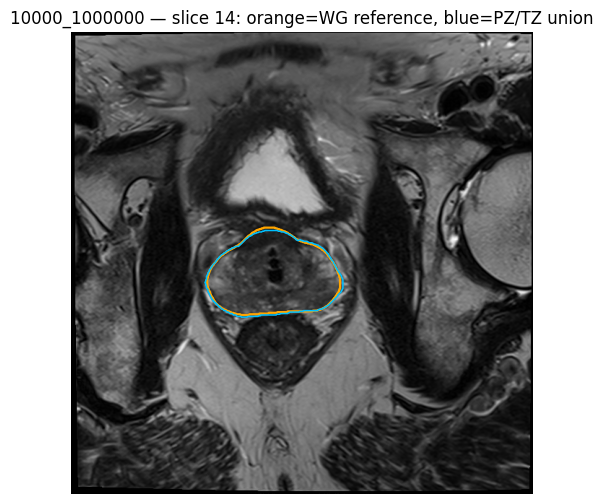

In [6]:
import matplotlib.pyplot as plt

def show_overlay(image, masks, title):
    volume = sitk.GetArrayFromImage(image)
    ref = sitk.GetArrayFromImage(masks["wg_ref"]) > 0
    union = sitk.GetArrayFromImage(masks["pz_tz_union"]) > 0
    positive = np.where(np.any(ref, axis=(1, 2)))[0]
    if len(positive) == 0:
        raise ValueError("Whole-gland reference mask is empty")
    z = int(positive[len(positive) // 2])
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(volume[z], cmap="gray")
    ax.contour(ref[z], levels=[0.5], colors=["orange"], linewidths=1.6)
    ax.contour(union[z], levels=[0.5], colors=["deepskyblue"], linewidths=1.1)
    ax.set_title(f"{title} — slice {z}: orange=WG reference, blue=PZ/TZ union")
    ax.axis("off")
    plt.show()

show_overlay(sample_image, sample_masks, f"{sample.patient_id}_{sample.study_id}")

## 4. PyRadiomics Configuration — Match Notebook 05

In [7]:
extractor = featureextractor.RadiomicsFeatureExtractor(
    normalize=True, normalizeScale=100, binWidth=5,
    resampledPixelSpacing=[0.5, 0.5, 3.0],
    interpolator=sitk.sitkBSpline,
)
extractor.disableAllImageTypes()
extractor.enableImageTypeByName("Original")
extractor.disableAllFeatures()
for name in ["firstorder", "shape", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]:
    extractor.enableFeatureClassByName(name)

def extract_features(image, mask, prefix):
    result = extractor.execute(image, mask)
    values = {f"{prefix}__{name}": float(value) for name, value in result.items()
              if not name.startswith("diagnostics_")}
    if len(values) != 107:
        raise ValueError(f"Expected 107 {prefix} features, got {len(values)}")
    if not np.isfinite(list(values.values())).all():
        raise ValueError(f"Non-finite {prefix} features")
    return values

for key, mask in sample_masks.items():
    features = extract_features(sample_image, mask, key)
    print(key, "features:", len(features))

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


wg_ref features: 107


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


pz_tz_union features: 107


## 5. Batch Extraction with Checkpoints

Each case is saved only if **both** feature sets succeed. The CSV stores 107 `wg_ref__` and 107 `pz_tz_union__` features. Restarting the notebook resumes from a valid existing result. If you change mask sources or parameters, delete/rename existing output first.

In [8]:
CHECKPOINT_INTERVAL = 25
if features_path.exists():
    previous = pd.read_csv(features_path, dtype={"patient_id": str, "study_id": str})
    if len([c for c in previous if c.startswith("wg_ref__")]) != 107 or len([c for c in previous if c.startswith("pz_tz_union__")]) != 107:
        raise ValueError("Existing feature file is incompatible with current extraction")
    feature_records = previous.to_dict("records")
else:
    feature_records = []
processed = {(r["patient_id"], r["study_id"]) for r in feature_records}
if quality_path.exists():
    quality_records = pd.read_csv(quality_path, dtype={"patient_id": str, "study_id": str}).to_dict("records")
else:
    quality_records = []
quality_processed = {(r["patient_id"], r["study_id"]) for r in quality_records}
failures = []
eligible = coverage_df.loc[coverage_df["eligible"]]
for index, row in enumerate(eligible.itertuples(index=False), start=1):
    key = (row.patient_id, row.study_id)
    if key in processed:
        continue
    try:
        image = sitk.ReadImage(row.t2w_path)
        zonal = sitk.ReadImage(row.zonal_path)
        whole = sitk.ReadImage(row.whole_path)
        masks, quality = prepare_masks(image, zonal, whole)
        record = {"patient_id": key[0], "study_id": key[1]}
        for prefix in ("wg_ref", "pz_tz_union"):
            record.update(extract_features(image, masks[prefix], prefix))
        feature_records.append(record)
        processed.add(key)
        if key not in quality_processed:
            quality_records.append({"patient_id": key[0], "study_id": key[1], **quality})
            quality_processed.add(key)
        if len(feature_records) % CHECKPOINT_INTERVAL == 0:
            pd.DataFrame(feature_records).to_csv(features_path, index=False)
            pd.DataFrame(quality_records).to_csv(quality_path, index=False)
            print(f"Checkpoint: {len(feature_records)} cases")
    except Exception as error:
        failures.append({"patient_id": key[0], "study_id": key[1], "error": str(error)})
        print(f"Failed {key}: {error}")
if feature_records:
    pd.DataFrame(feature_records).to_csv(features_path, index=False)
if quality_records:
    pd.DataFrame(quality_records).to_csv(quality_path, index=False)
pd.DataFrame(failures, columns=["patient_id", "study_id", "error"]).to_csv(failures_path, index=False)
print("Completed cases:", len(feature_records))
print("Failures in current execution:", len(failures))
print("Features saved:", features_path)

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

Checkpoint: 25 cases


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

Checkpoint: 50 cases


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

...

Checkpoint: 1450 cases


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

Checkpoint: 1475 cases


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Avera

Checkpoint: 1500 cases
Completed cases: 1500
Failures in current execution: 0
Features saved: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\reference_whole_gland_t2w_radiomics.csv


## 6. Quality and Coverage Report

In [9]:
features_df = pd.read_csv(features_path, dtype={"patient_id": str, "study_id": str})
quality_df = pd.read_csv(quality_path, dtype={"patient_id": str, "study_id": str})
ids = ["patient_id", "study_id"]
assert not features_df.duplicated(ids).any()
assert not quality_df.duplicated(ids).any()
wg_cols = [x for x in features_df if x.startswith("wg_ref__")]
union_cols = [x for x in features_df if x.startswith("pz_tz_union__")]
assert len(wg_cols) == len(union_cols) == 107
assert np.isfinite(features_df[wg_cols + union_cols].to_numpy(dtype=float)).all()
print("Cases:", len(features_df), "Reference features:", len(wg_cols), "Union features:", len(union_cols))
print("Anatomical agreement summary:")
display(quality_df[["union_vs_reference_dice", "union_inside_reference_fraction", "reference_covered_by_union_fraction"]].describe())
print("Cases with lowest agreement:")
display(quality_df.nsmallest(10, "union_vs_reference_dice"))
joined = features_df.merge(splits_df[ids + ["split"]], on=ids, how="left", validate="one_to_one")
print("Cases by split:")
display(joined["split"].value_counts(dropna=False))
if joined["split"].isna().any():
    raise ValueError("Extracted cases without original split assignment")
print("Note: PZ/TZ union is not a complete whole-gland reference unless agreement supports it.")

Cases: 1500 Reference features: 107 Union features: 107
Anatomical agreement summary:


,union_vs_reference_dice,union_inside_reference_fraction,reference_covered_by_union_fraction
count,1500.000000,1500.000000,1500.000000
mean,0.930957,0.928742,0.935064
std,0.044791,0.047194,0.057883
min,0.000000,0.000000,0.000000
25%,0.921833,0.908347,0.919967
50%,0.939477,0.933473,0.949937
75%,0.952992,0.957702,0.967640
max,0.979926,0.999036,0.999832


Cases with lowest agreement:


,patient_id,study_id,pz_voxels,tz_voxels,union_voxels,reference_voxels,union_vs_reference_dice,union_inside_reference_fraction,reference_covered_by_union_fraction
1070,11050,1001070,75829,32055,107884,184476,0.000000,0.000000,0.000000
96,10096,1000096,12411,16663,29074,33940,0.522138,0.565832,0.484708
960,10941,1000960,15384,8791,24175,23733,0.619562,0.613899,0.625332
852,10836,1000852,13976,23500,37476,50256,0.676925,0.792347,0.590855
820,10804,1000820,18757,22709,41466,56678,0.692085,0.819032,0.599210
481,10473,1000481,22811,18528,41339,48007,0.697021,0.753235,0.648614
1480,11456,1001480,16880,13868,30748,38952,0.727461,0.824509,0.650852
976,10957,1000976,21295,22623,43918,51751,0.732003,0.797281,0.676605
1021,11002,1001021,28906,26395,55301,67106,0.743111,0.822426,0.677749
1398,11375,1001398,21372,24972,46344,48095,0.744290,0.758351,0.730741


Cases by split:


split
train         1050
test           225
validation     225
Name: count, dtype: int64

Note: PZ/TZ union is not a complete whole-gland reference unless agreement supports it.


In [10]:

case_row = coverage_df.loc[
    (coverage_df["patient_id"].astype(str) == "11050")
    & (coverage_df["study_id"].astype(str) == "1001070")
].iloc[0]

t2w_image = sitk.ReadImage(case_row["t2w_path"])
zonal_image = sitk.ReadImage(case_row["zonal_path"])
reference_image = sitk.ReadImage(case_row["whole_path"])

print("T2W origin:", t2w_image.GetOrigin())
print("Zonal origin:", zonal_image.GetOrigin())
print("Reference origin:", reference_image.GetOrigin())

print("T2W spacing:", t2w_image.GetSpacing())
print("Zonal spacing:", zonal_image.GetSpacing())
print("Reference spacing:", reference_image.GetSpacing())

print("T2W size:", t2w_image.GetSize())
print("Zonal size:", zonal_image.GetSize())
print("Reference size:", reference_image.GetSize())

print("T2W direction:", t2w_image.GetDirection())
print("Zonal direction:", zonal_image.GetDirection())
print("Reference direction:", reference_image.GetDirection())


T2W origin: (-92.279447321886, -86.590177859754, -25.540836738613)
Zonal origin: (-91.3494644165039, -78.92755889892578, -2.6576123237609863)
Reference origin: (-92.27944946289062, -86.59017944335938, -25.540836334228516)
T2W spacing: (0.28125, 0.28125, 3.4500000138306155)
Zonal spacing: (0.28125, 0.28125, 3.450000047683716)
Reference spacing: (0.28125, 0.28125, 3.450000047683716)
T2W size: (640, 640, 37)
Zonal size: (640, 640, 23)
Reference size: (640, 640, 37)
T2W direction: (0.999258266441154, 1.667079998352028e-10, 0.038508660701451806, -0.012227581151884282, 0.9482488703359125, 0.3172925561147625, -0.03651579395540542, -0.3175280773516975, 0.9475455223286852)
Zonal direction: (0.9992582663791776, -5.383761153151073e-10, 0.03850866105123434, -0.012227580111215938, 0.9482488741213998, 0.3172925630922534, -0.036515795999871294, -0.31752806604692074, 0.9475455199780058)
Reference direction: (0.9992583534801338, -1.3878505879726532e-05, 0.03850639999442363, -0.012213701932352902, 0.948

## 7. Interpretation

- `wg_ref__`: features from the independent anatomical **whole-gland reference** mask.
- `pz_tz_union__`: features from the physical-space union of two zonal labels; anatomical completeness must be inspected.
- The original notebook 05 features are from **predicted** whole-gland masks.
- Notebook 11 will compare all regions on the **same case intersection** using unchanged saved splits.
- These comparisons are **exploratory** because earlier test-set findings have already informed the research direction.